# 10 — Crypto risk-on / risk-off BTC/ETH (Projet 6, recherche)

Poche satellite **expérimentale** : non branchée sur le rapport mensuel, sans levier, sans ordre.

Règle du guide : risk-on si BTC > MA 200 jours et momentum 90 jours > 0, allocation 70 % BTC / 30 % ETH, sinon cash. Données en euros (BTC-EUR, ETH-EUR), rebalancement mensuel, frais 0,25 %.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.crypto_signals import (BTC, ETH, STRATEGY_LABELS, generate_crypto_report, run_crypto_study,
                                sleeve_comparison, trend_signal)
from src.data_loader import download_prices, load_prices, save_prices, validate_prices
from src.features import to_monthly_prices

crypto_path = PROJECT_ROOT / 'data' / 'processed' / 'crypto_prices.csv'
if not crypto_path.exists():  # premier lancement : téléchargement explicite (yfinance)
    save_prices(validate_prices(download_prices([BTC, ETH], start='2015-01-01')), crypto_path)
crypto = load_prices(crypto_path)
universe = load_prices(PROJECT_ROOT / 'data' / 'processed' / 'universe_prices.csv')
print('Crypto :', crypto.index.min().date(), '→', crypto.index.max().date())

Crypto : 2015-01-01 → 2026-09-23


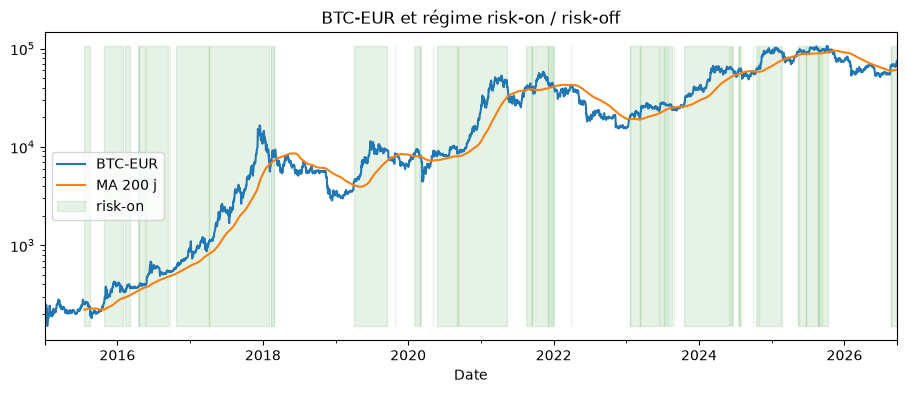

Part du temps en risk-on : 52%


In [2]:
signal = trend_signal(crypto[BTC])
fig, ax = plt.subplots(figsize=(11, 4))
crypto[BTC].plot(ax=ax, logy=True, label='BTC-EUR')
crypto[BTC].rolling(200).mean().plot(ax=ax, logy=True, label='MA 200 j')
ax.fill_between(signal.index, crypto[BTC].min(), crypto[BTC].max(), where=signal, alpha=0.1, color='green', label='risk-on')
ax.set_title('BTC-EUR et régime risk-on / risk-off')
ax.legend()
plt.show()
print(f"Part du temps en risk-on : {signal.mean():.0%}")

,cagr,volatility,sharpe,max_drawdown,n_periods,avg_exposure
Buy & Hold BTC,26.6%,67.7%,0.67,-74.4%,105.000000,100%
Buy & Hold 70/30 BTC/ETH,29.8%,71.0%,0.70,-75.6%,105.000000,100%
Risk-on/off BTC,27.5%,49.1%,0.72,-56.4%,105.000000,47%
Risk-on/off 70/30,38.0%,49.2%,0.87,-46.1%,105.000000,47%
Risk-on/off 70/30 + VT,26.3%,34.8%,0.83,-30.6%,105.000000,34%


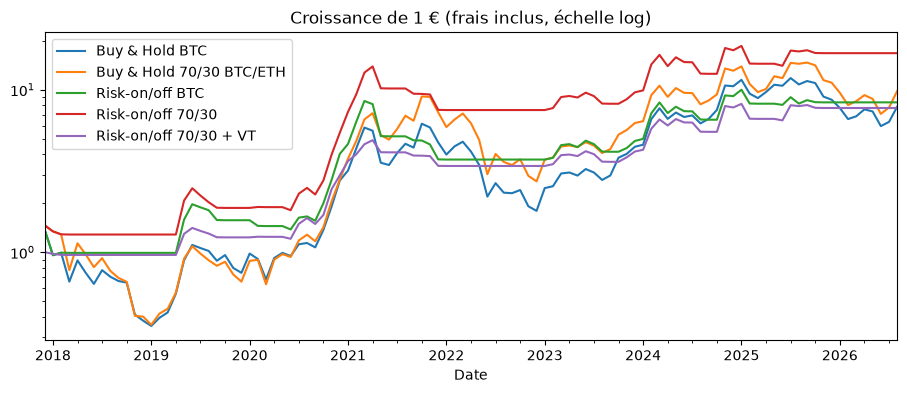

In [3]:
study = run_crypto_study(crypto)
metrics = pd.DataFrame(study['metrics']).T.rename(index=STRATEGY_LABELS)
display(metrics.style.format({'cagr': '{:.1%}', 'volatility': '{:.1%}', 'sharpe': '{:.2f}',
                              'max_drawdown': '{:.1%}', 'avg_exposure': '{:.0%}'}))
equity = pd.DataFrame({STRATEGY_LABELS[k]: (1 + v).cumprod() for k, v in study['returns'].items()})
ax = equity.plot(figsize=(11, 4), logy=True, title='Croissance de 1 € (frais inclus, échelle log)')
plt.show()

## Effet patrimonial : 95/5 et 90/10

Cœur = Buy & Hold CW8.PA (PEA), rebalancement mensuel entre cœur et poche crypto (frais de ce rebalancement ignorés).

In [4]:
core = to_monthly_prices(universe['CW8.PA']).pct_change(fill_method=None)
sleeves = sleeve_comparison(core, {k: study['returns'][k] for k in ('bh_basket', 'roro_basket', 'roro_basket_vt')})
display(sleeves.style.format({'cagr': '{:.1%}', 'volatility': '{:.1%}', 'sharpe': '{:.2f}', 'max_drawdown': '{:.1%}'}))

,cagr,volatility,sharpe,max_drawdown,n_periods
portefeuille,,,,,
100 % cœur,12.4%,13.6%,0.93,-18.6%,105
95% cœur + 5% Buy & Hold 70/30 BTC/ETH,14.3%,14.7%,0.99,-19.0%,105
90% cœur + 10% Buy & Hold 70/30 BTC/ETH,16.1%,16.5%,0.99,-19.4%,105
95% cœur + 5% Risk-on/off 70/30,14.1%,13.5%,1.05,-17.7%,105
90% cœur + 10% Risk-on/off 70/30,15.8%,13.9%,1.13,-16.7%,105
95% cœur + 5% Risk-on/off 70/30 + VT,13.3%,13.4%,1.00,-17.7%,105
90% cœur + 10% Risk-on/off 70/30 + VT,14.2%,13.5%,1.06,-16.8%,105


In [5]:
weekly = run_crypto_study(crypto, freq='W-FRI')
display(pd.DataFrame(weekly['metrics']).T.rename(index=STRATEGY_LABELS)[['cagr', 'sharpe', 'max_drawdown', 'avg_exposure']]
        .style.format({'cagr': '{:.1%}', 'sharpe': '{:.2f}', 'max_drawdown': '{:.1%}', 'avg_exposure': '{:.0%}'}))
print('Variante hebdomadaire : sensibilité à la fréquence de rebalancement (non retenue par défaut).')

,cagr,sharpe,max_drawdown,avg_exposure
Buy & Hold BTC,30.8%,0.73,-81.0%,100%
Buy & Hold 70/30 BTC/ETH,33.8%,0.77,-83.5%,100%
Risk-on/off BTC,26.6%,0.71,-68.1%,48%
Risk-on/off 70/30,36.4%,0.88,-61.6%,48%
Risk-on/off 70/30 + VT,21.8%,0.78,-48.5%,34%


Variante hebdomadaire : sensibilité à la fréquence de rebalancement (non retenue par défaut).


In [6]:
report = generate_crypto_report(study, sleeves, PROJECT_ROOT / 'reports' / 'crypto_report.md')
print('Rapport :', report)

Rapport : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab\reports\crypto_report.md


## Conclusion et limites

- Le filtre risk-on/off se juge au **drawdown** et au Sharpe de la poche, pas au rendement final.
- Historique court (ETH depuis fin 2017), dominé par quelques cycles extrêmes : forte incertitude.
- Poche hors PEA : fiscalité, frais et risque de plateforme à étudier avant tout usage réel.
- Guide : 1 à 3 % du patrimoine au début, 5 % au maximum, **après** paper trading. Aucun ordre n'est exécuté.